# Assignment: Customer Churn Prediction using Machine Learning
### Dataset: Telco Customer Churn Dataset (Kaggle)

### Objective
Telecom companies face major losses when customers discontinue their service (i.e., churn).

In this project, you will analyze customer data to predict whether a customer will churn and evaluate the performance of multiple classification models.

- You will apply and compare three key supervised learning algorithms:

- Logistic Regression

- K-Nearest Neighbors (KNN)

- Decision Tree

- Random Forest Classifier

- You will also explore evaluation metrics such as the confusion matrix, precision, recall, F1 score, and ROC-AUC to assess model performance.

## Tasks and Deliverables
### Part 1: Data Understanding and Preparation

- Load the Telco Customer Churn dataset.

Explore the dataset:

- Check for missing values and data types.

- Summarize key statistics and visualize important relationships.

- Explore the churn distribution (target balance).

Clean and preprocess the data:

- Handle missing or blank values (e.g., in TotalCharges).

- Encode categorical features appropriately.

- Scale numerical features if required (especially for KNN).

- Split the data into training and testing sets.

## Part 2: Model Implementation

A. Logistic Regression

- Explain the concept of logistic regression and sigmoid function.

- Train a logistic regression model to predict customer churn.

- Evaluate its performance using classification metrics.

B. K-Nearest Neighbors (KNN)

- Explain how KNN predicts outcomes based on distance to neighboring points.

- Experiment with different values of K (e.g., 3, 5, 7, 9) and compare results.

- Discuss the impact of scaling and the choice of K on performance.

C. Decision Tree

- Explain how decision trees work.

- Train a decision tree classifier.

- Experiment with hyperparameters like max_depth or min_samples_leaf to avoid overfitting.

D. Random Forest Classifier

- Introduce Random Forest as an ensemble of decision trees.

- Train a Random Forest model and tune key hyperparameters such as:

- n_estimators (number of trees)

- max_depth

- max_features

- Compare feature importances with the single decision tree model.

- Evaluate

## Part 3: Model Evaluation

- For each model, compute and interpret:

- Confusion Matrix

- True Positives (TP), False Positives (FP), True Negatives (TN), False Negatives (FN)

- Precision, Recall, F1 Score, and Accuracy

- Plot and interpret the ROC curve and compute the ROC-AUC score for each model.

- Compare all models using a performance summary table.

Discuss:

- Which model performs best overall?

- Which metric (precision or recall) is more important for this business problem?

- Trade-offs between model interpretability and performance.

### Part 4: Insights and Conclusion

- Write a brief report summarizing:

- Key factors that influence customer churn.

- Which model you recommend for deployment and why.

- Business implications of false positives and false negatives.

- Limitations of your approach and potential improvements.

# Part 1: Data Understanding and Preparation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                              precision_score, recall_score, f1_score, roc_curve, roc_auc_score)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

pd.set_option("display.max_columns", None)


## 1. Load the dataset

In [ ]:
file_path = "/content/drive/MyDrive/Colab Notebooks/Dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Shape:", df.shape)
df.head()


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Explore the dataset: data types and missing values

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
# Check for missing/blank values in every column
print("Null counts per column:")
print(df.isnull().sum())

print("\nEmpty-string / whitespace-only counts per object column:")
for c in df.select_dtypes(include="object").columns:
    blanks = (df[c].astype(str).str.strip() == "").sum()
    if blanks > 0:
        print(f"  {c}: {blanks} blank entries")


Null counts per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Empty-string / whitespace-only counts per object column:
  TotalCharges: 11 blank entries


/tmp/ipykernel_555/2659674922.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes(include="object").columns:


## 3. Summary statistics

In [ ]:
df.describe(include="number")


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
df.describe(include="object")


/tmp/ipykernel_555/3764884355.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


## 4. Churn distribution (target balance)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


/tmp/ipykernel_555/1740823553.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Churn", data=df, ax=ax[0], palette=["#2E86AB", "#E63946"])


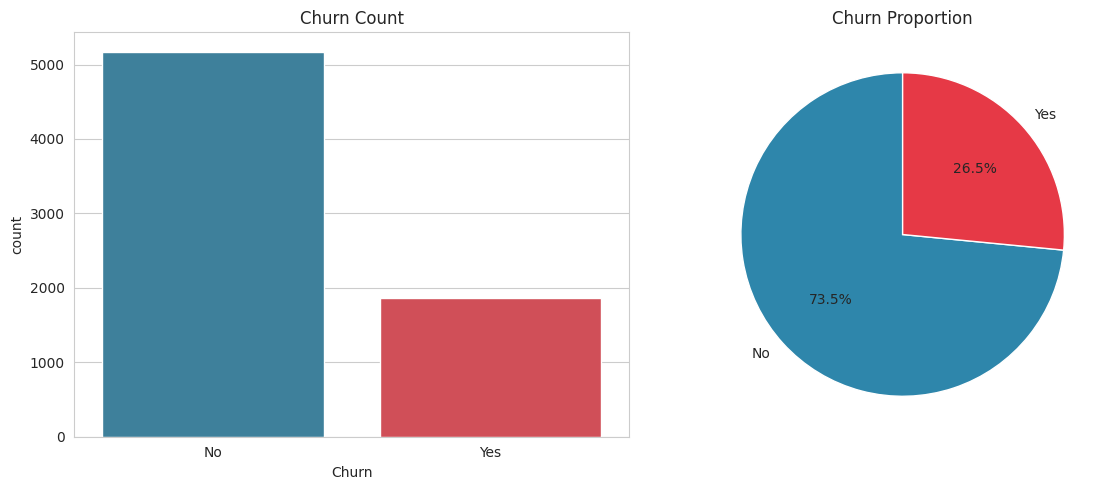

In [ ]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True) * 100
print(churn_counts)
print(churn_pct.round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x="Churn", data=df, ax=ax[0], palette=["#2E86AB", "#E63946"])
ax[0].set_title("Churn Count")
ax[1].pie(churn_counts, labels=churn_counts.index, autopct="%1.1f%%",
          colors=["#2E86AB", "#E63946"], startangle=90)
ax[1].set_title("Churn Proportion")
plt.tight_layout()
plt.show()


**Observation:** The target is imbalanced — roughly 73% of customers did **not** churn and 27% **did** churn. This class imbalance matters when choosing evaluation metrics later: accuracy alone can be misleading, so precision, recall, F1, and ROC-AUC are all reported.

## 5. Visualize important relationships

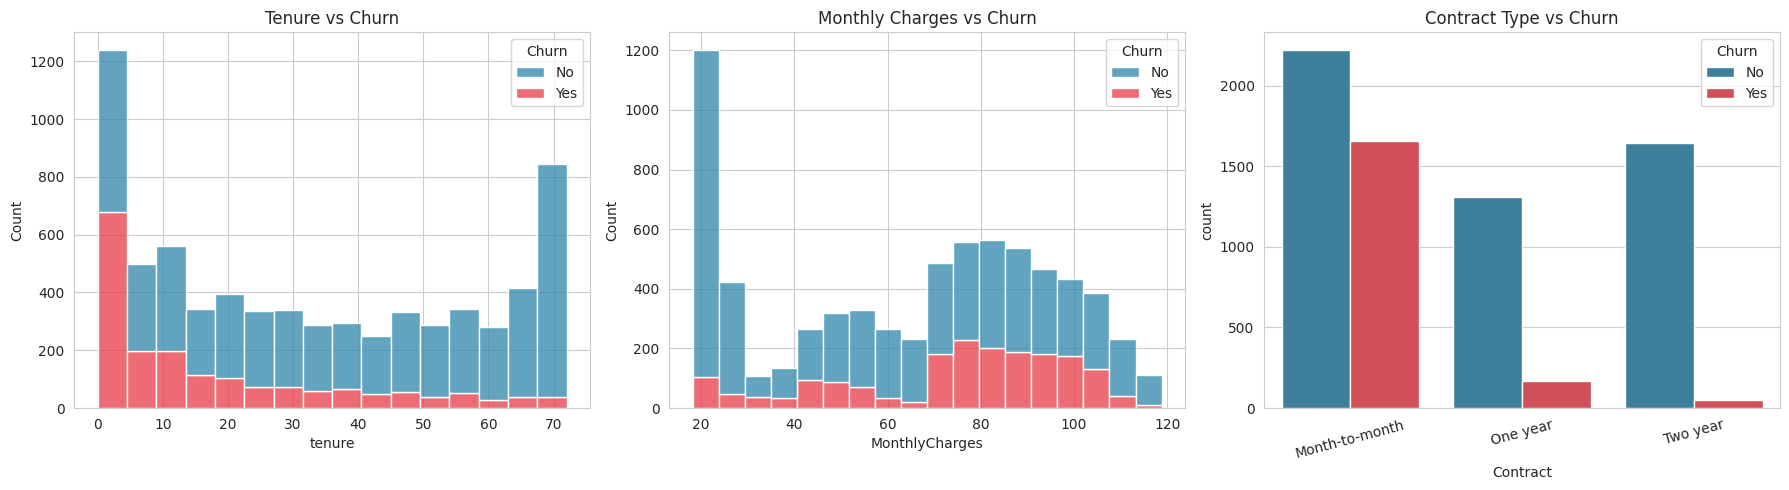

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack", ax=ax[0], palette=["#2E86AB", "#E63946"])
ax[0].set_title("Tenure vs Churn")

sns.histplot(data=df, x="MonthlyCharges", hue="Churn", multiple="stack", ax=ax[1], palette=["#2E86AB", "#E63946"])
ax[1].set_title("Monthly Charges vs Churn")

sns.countplot(data=df, x="Contract", hue="Churn", ax=ax[2], palette=["#2E86AB", "#E63946"])
ax[2].set_title("Contract Type vs Churn")
ax[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


**Observations:**
- Customers with **short tenure** (new customers) churn far more often than long-tenure customers.
- Customers with **higher monthly charges** churn more often.
- Customers on **month-to-month contracts** churn at a much higher rate than those on one- or two-year contracts — contract type looks like a strong predictor.

/tmp/ipykernel_555/3807244997.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax[0], palette=["#2E86AB", "#E63946"])
/tmp/ipykernel_555/3807244997.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="tenure", ax=ax[1], palette=["#2E86AB", "#E63946"])


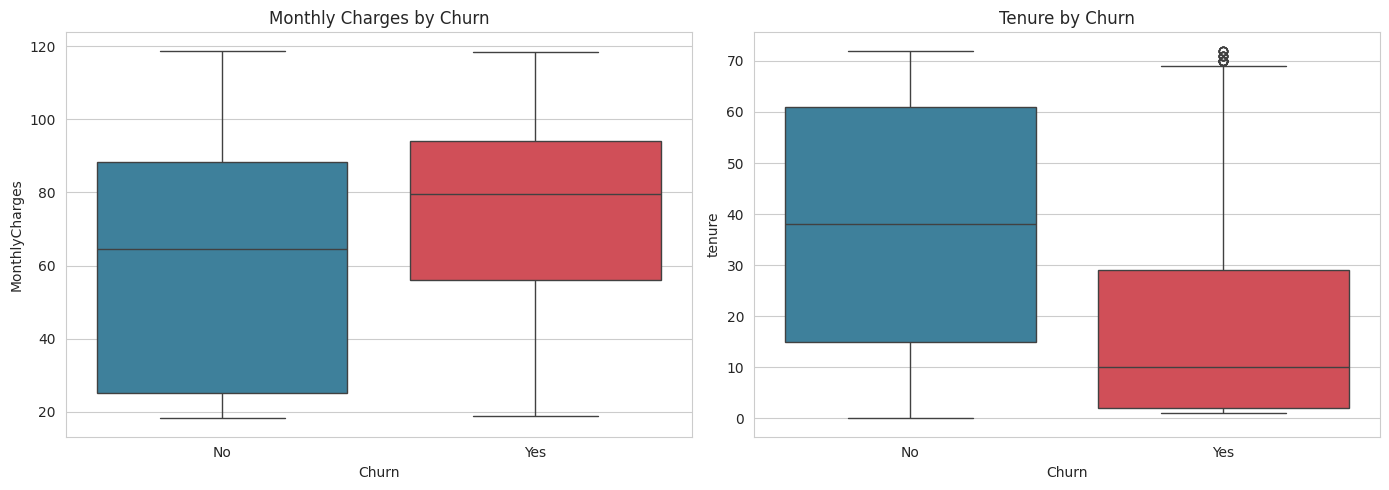

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax[0], palette=["#2E86AB", "#E63946"])
ax[0].set_title("Monthly Charges by Churn")
sns.boxplot(data=df, x="Churn", y="tenure", ax=ax[1], palette=["#2E86AB", "#E63946"])
ax[1].set_title("Tenure by Churn")
plt.tight_layout()
plt.show()


## 6. Clean the data

In [ ]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Rows with missing TotalCharges:", df["TotalCharges"].isnull().sum())
print(df.loc[df["TotalCharges"].isnull(), ["tenure", "MonthlyCharges", "TotalCharges"]])

# These are all tenure == 0 customers -> fill with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("\nMissing values after cleaning:", df["TotalCharges"].isnull().sum())


Rows with missing TotalCharges: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN

Missing values after cleaning: 0


In [ ]:
# Drop customerID - it's just an identifier, not predictive
df.drop(columns=["customerID"], inplace=True)


## 7. Encode categorical features

In [ ]:
# Target variable
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Identify binary vs multi-category object columns
obj_cols = df.select_dtypes(include="object").columns.tolist()
binary_cols = [c for c in obj_cols if df[c].nunique() == 2]
multi_cols = [c for c in obj_cols if df[c].nunique() > 2]

print("Binary columns (label encode):", binary_cols)
print("Multi-category columns (one-hot encode):", multi_cols)

le = LabelEncoder()
for c in binary_cols:
    df[c] = le.fit_transform(df[c])

df = pd.get_dummies(df, columns=multi_cols, drop_first=True)

print("\nFinal shape after encoding:", df.shape)
df.head()


Binary columns (label encode): ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
Multi-category columns (one-hot encode): ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

Final shape after encoding: (7043, 31)


/tmp/ipykernel_555/340538138.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include="object").columns.tolist()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,0,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,1,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


## 8. Feature/target split, scaling, and train/test split

KNN and Logistic Regression are distance/gradient based and are sensitive to feature scale, so numerical features are standardized. Tree-based models (Decision Tree, Random Forest) are scale-invariant, but using the same scaled data for all four models keeps the comparison simple and doesn't hurt the tree models.

In [ ]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train churn rate:", y_train.mean().round(3), " Test churn rate:", y_test.mean().round(3))

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])


Train shape: (5634, 30)  Test shape: (1409, 30)
Train churn rate: 0.265  Test churn rate: 0.265


# Part 2: Model Implementation
We will train four classifiers and store their predictions/probabilities so they can all be compared side-by-side in Part 3:
- Logistic Regression
- K-Nearest Neighbors (KNN)
- Decision Tree
- Random Forest

In [ ]:
# Dictionary to hold results for later comparison
results = {}

def evaluate_model(name, model, X_te, y_te, y_pred, y_prob):
    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred)
    rec = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    auc = roc_auc_score(y_te, y_prob)
    cm = confusion_matrix(y_te, y_pred)
    results[name] = {"accuracy": acc, "precision": prec, "recall": rec,
                      "f1": f1, "roc_auc": auc, "confusion_matrix": cm,
                      "y_prob": y_prob, "y_pred": y_pred}
    print(f"--- {name} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")
    print("Confusion Matrix:\n", cm)


## A. Logistic Regression
Logistic Regression is a supervised machine learning algorithm mainly used for binary classification.

In this project, there are two possible outcomes:

- 0 → Customer will not churn
- 1 → Customer will churn

Unlike Linear Regression, which predicts continuous values, Logistic Regression predicts the probability that an observation belongs to a particular class.

For example:
```
Customer A → Probability of Churn = 0.82
Customer B → Probability of Churn = 0.21
```
Using a default threshold of 0.5:
```
Probability >= 0.5 → Churn
Probability < 0.5  → No Churn
```

### The sigmoid function is:

Logistic Regression uses the sigmoid function to convert the model's output into a probability between 0 and 1.

The sigmoid function is:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$
	​

where:

z=w1​x1​+w2​x2​+⋯+wn​xn​+b

The sigmoid function produces values between 0 and 1.
```
Input z → Sigmoid Function → Probability
```
For example:
```
z = 2     → Probability ≈ 0.88
z = 0     → Probability = 0.50
z = -2    → Probability ≈ 0.12
```
Therefore, Logistic Regression can convert the model's output into a churn probability.

In [ ]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)
y_prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

evaluate_model("Logistic Regression", log_reg, X_test_scaled, y_test, y_pred_lr, y_prob_lr)


--- Logistic Regression ---
Accuracy : 0.8062
Precision: 0.6593
Recall   : 0.5588
F1 Score : 0.6049
ROC-AUC  : 0.8422
Confusion Matrix:
 [[927 108]
 [165 209]]


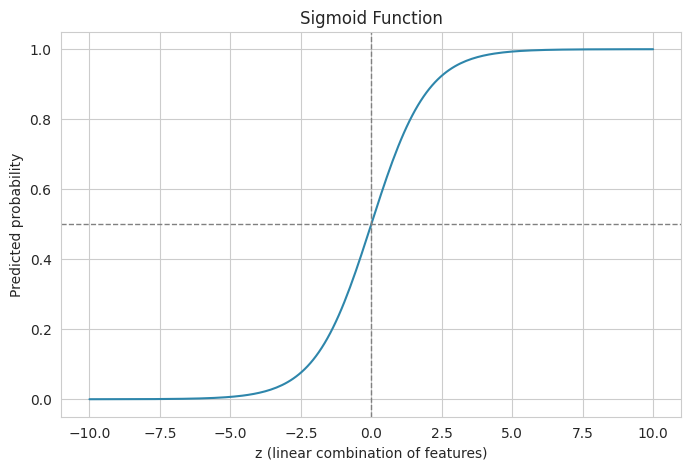

In [ ]:
# Sigmoid function illustration
z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))
plt.plot(z, sigmoid, color="#2E86AB")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.axvline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Sigmoid Function")
plt.xlabel("z (linear combination of features)")
plt.ylabel("Predicted probability")
plt.show()


In [ ]:
# Top coefficients (most influential features)
coef_df = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "coefficient": log_reg.coef_[0]
}).sort_values("coefficient", key=abs, ascending=False).head(10)
coef_df


,feature,coefficient
26,Contract_Two year,-1.313803
4,tenure,-1.257131
11,InternetService_Fiber optic,1.180666
25,Contract_One year,-0.683857
8,TotalCharges,0.527772
5,PhoneService,-0.520750
7,MonthlyCharges,-0.466504
28,PaymentMethod_Electronic check,0.392775
22,StreamingTV_Yes,0.374831
6,PaperlessBilling,0.374218


## B. K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a distance-based classification algorithm.

Instead of learning a specific mathematical relationship during training, KNN stores the training observations and compares a new observation with its nearest neighbors.

Suppose:
```
K = 5
```
For a new customer, KNN finds the 5 customers that are closest to that customer.

If:
```
4 neighbors → Churn
1 neighbor   → No Churn
```
then the model predicts:
```
Churn
```

In [ ]:
k_values = [3, 5, 7, 9]
knn_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred_k = knn.predict(X_test_scaled)
    y_prob_k = knn.predict_proba(X_test_scaled)[:, 1]
    acc = accuracy_score(y_test, y_pred_k)
    f1 = f1_score(y_test, y_pred_k)
    auc = roc_auc_score(y_test, y_prob_k)
    knn_scores.append({"k": k, "accuracy": acc, "f1": f1, "roc_auc": auc})
    print(f"k={k}: accuracy={acc:.4f}, f1={f1:.4f}, roc_auc={auc:.4f}")

knn_scores_df = pd.DataFrame(knn_scores)
knn_scores_df


k=3: accuracy=0.7601, f1=0.5481, roc_auc=0.7490
k=5: accuracy=0.7630, f1=0.5523, roc_auc=0.7931
k=7: accuracy=0.7708, f1=0.5605, roc_auc=0.8031


k=9: accuracy=0.7729, f1=0.5699, roc_auc=0.8079


,k,accuracy,f1,roc_auc
0,3,0.760114,0.548128,0.749014
1,5,0.762952,0.552279,0.793145
2,7,0.770759,0.560544,0.803128
3,9,0.772889,0.569892,0.807901


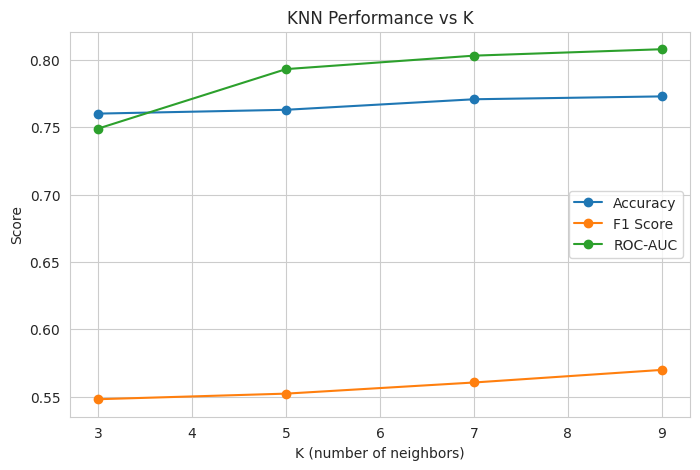

In [ ]:
plt.plot(knn_scores_df["k"], knn_scores_df["accuracy"], marker="o", label="Accuracy")
plt.plot(knn_scores_df["k"], knn_scores_df["f1"], marker="o", label="F1 Score")
plt.plot(knn_scores_df["k"], knn_scores_df["roc_auc"], marker="o", label="ROC-AUC")
plt.xlabel("K (number of neighbors)")
plt.ylabel("Score")
plt.title("KNN Performance vs K")
plt.legend()
plt.show()


In [ ]:
# Pick the best K by F1 score and use it as our official KNN model
best_k = int(knn_scores_df.loc[knn_scores_df["f1"].idxmax(), "k"])
print("Best K selected:", best_k)

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_scaled, y_train)
y_pred_knn = knn_best.predict(X_test_scaled)
y_prob_knn = knn_best.predict_proba(X_test_scaled)[:, 1]

evaluate_model(f"KNN (k={best_k})", knn_best, X_test_scaled, y_test, y_pred_knn, y_prob_knn)


Best K selected: 9


--- KNN (k=9) ---
Accuracy : 0.7729
Precision: 0.5730
Recall   : 0.5668
F1 Score : 0.5699
ROC-AUC  : 0.8079
Confusion Matrix:
 [[877 158]
 [162 212]]


**Impact of scaling and K:**
- Without scaling, KNN's distance calculations would be dominated by `TotalCharges`/`MonthlyCharges`, effectively ignoring most categorical dummy features. Scaling puts every feature on a comparable footing.
- A **small K** (e.g., 3) makes the model sensitive to noise/outliers (low bias, high variance — can overfit). A **large K** smooths the decision boundary and is more robust but can underfit and blur the boundary between classes. The sweet spot here is selected empirically using F1 score above.

## C. Decision Tree

A Decision Tree is a supervised learning algorithm that makes predictions by repeatedly splitting the data according to feature values.

It contains:

- Root node
- Decision nodes
- Branches
- Leaf nodes

Decision Trees are relatively easy to understand and interpret.

In [ ]:
# Baseline (unconstrained) tree - likely overfits
dt_full = DecisionTreeClassifier(random_state=42)
dt_full.fit(X_train_scaled, y_train)
print("Unconstrained tree depth:", dt_full.get_depth())
print("Train accuracy:", round(accuracy_score(y_train, dt_full.predict(X_train_scaled)), 4))
print("Test accuracy :", round(accuracy_score(y_test, dt_full.predict(X_test_scaled)), 4))


Unconstrained tree depth: 23
Train accuracy: 0.998
Test accuracy : 0.731


In [ ]:
# Hyperparameter search over max_depth / min_samples_leaf to control overfitting
depth_options = [3, 4, 5, 6, 8, 10, None]
leaf_options = [1, 5, 10, 20]

tree_search = []
for d in depth_options:
    for leaf in leaf_options:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=42)
        dt.fit(X_train_scaled, y_train)
        train_acc = accuracy_score(y_train, dt.predict(X_train_scaled))
        test_f1 = f1_score(y_test, dt.predict(X_test_scaled))
        test_acc = accuracy_score(y_test, dt.predict(X_test_scaled))
        tree_search.append({"max_depth": d, "min_samples_leaf": leaf,
                             "train_acc": train_acc, "test_acc": test_acc, "test_f1": test_f1})

tree_search_df = pd.DataFrame(tree_search).sort_values("test_f1", ascending=False)
tree_search_df.head(10)


,max_depth,min_samples_leaf,train_acc,test_acc,test_f1
11,5.0,20,0.801562,0.795600,0.586207
10,5.0,10,0.801562,0.795600,0.586207
9,5.0,5,0.801917,0.794180,0.582133
8,5.0,1,0.802272,0.794180,0.582133
18,8.0,10,0.826944,0.779276,0.581427
16,8.0,1,0.835818,0.781405,0.580381
19,8.0,20,0.820731,0.790632,0.580370
14,6.0,10,0.808129,0.801278,0.571865
7,4.0,20,0.792155,0.795600,0.571429
6,4.0,10,0.792155,0.795600,0.571429


In [ ]:
best_params = tree_search_df.iloc[0]
best_depth = None if pd.isna(best_params["max_depth"]) else int(best_params["max_depth"])
best_leaf = int(best_params["min_samples_leaf"])
print("Selected max_depth:", best_depth, " min_samples_leaf:", best_leaf)

dt_best = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=best_leaf, random_state=42)
dt_best.fit(X_train_scaled, y_train)

y_pred_dt = dt_best.predict(X_test_scaled)
y_prob_dt = dt_best.predict_proba(X_test_scaled)[:, 1]

evaluate_model("Decision Tree", dt_best, X_test_scaled, y_test, y_pred_dt, y_prob_dt)


Selected max_depth: 5  min_samples_leaf: 20
--- Decision Tree ---
Accuracy : 0.7956
Precision: 0.6335
Recall   : 0.5455
F1 Score : 0.5862
ROC-AUC  : 0.8268
Confusion Matrix:
 [[917 118]
 [170 204]]


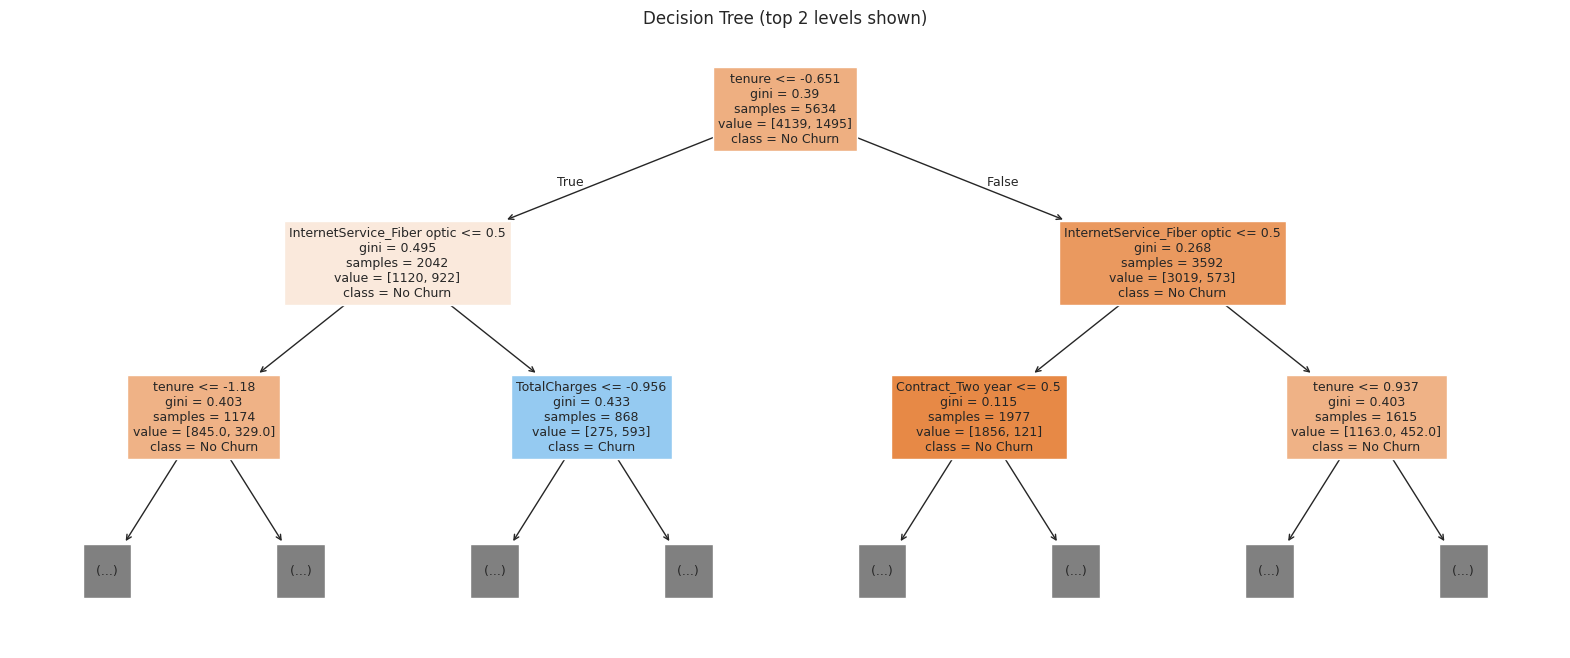

In [ ]:
plt.figure(figsize=(20, 8))
plot_tree(dt_best, max_depth=2, feature_names=X_train_scaled.columns, class_names=["No Churn", "Churn"],
          filled=True, fontsize=9)
plt.title("Decision Tree (top 2 levels shown)")
plt.show()


**Overfitting control:** the unconstrained tree memorizes the training data (train accuracy far above test accuracy). By tuning `max_depth` and `min_samples_leaf` and selecting the combination with the best **test** F1 score, we get a tree that generalizes better, at some cost to how perfectly it fits the training data.

## D. Random Forest Classifier
Random Forest is an ensemble learning algorithm that combines multiple Decision Trees.

Instead of relying on one tree:
```
Decision Tree 1
Decision Tree 2
Decision Tree 3
...
Decision Tree N
        ↓
Combine Predictions
        ↓
Final Prediction
```
Each tree is trained using a different random sample of the data and features.

The final classification is generally based on the majority vote of the trees.

Because Random Forest combines many trees, it is usually more robust than a single Decision Tree.

In [ ]:
n_estimators_options = [100, 200, 300]
max_depth_options = [None, 8, 12]
max_features_options = ["sqrt", "log2"]

rf_search = []
for n in n_estimators_options:
    for d in max_depth_options:
        for mf in max_features_options:
            rf = RandomForestClassifier(n_estimators=n, max_depth=d, max_features=mf,
                                         random_state=42, n_jobs=-1)
            rf.fit(X_train_scaled, y_train)
            test_f1 = f1_score(y_test, rf.predict(X_test_scaled))
            test_auc = roc_auc_score(y_test, rf.predict_proba(X_test_scaled)[:, 1])
            rf_search.append({"n_estimators": n, "max_depth": d, "max_features": mf,
                               "test_f1": test_f1, "test_auc": test_auc})

rf_search_df = pd.DataFrame(rf_search).sort_values("test_f1", ascending=False)
rf_search_df.head(10)


,n_estimators,max_depth,max_features,test_f1,test_auc
10,200,12.0,sqrt,0.599705,0.838411
4,100,12.0,sqrt,0.592262,0.837078
17,300,12.0,log2,0.588060,0.837605
16,300,12.0,sqrt,0.588060,0.837312
14,300,8.0,sqrt,0.574961,0.844360
11,200,12.0,log2,0.573152,0.836101
5,100,12.0,log2,0.566210,0.835718
8,200,8.0,sqrt,0.565688,0.844429
2,100,8.0,sqrt,0.564341,0.843773
7,200,NaN,log2,0.561562,0.825818


In [ ]:
best_rf_params = rf_search_df.iloc[0]
best_n = int(best_rf_params["n_estimators"])
best_rf_depth = None if pd.isna(best_rf_params["max_depth"]) else int(best_rf_params["max_depth"])
best_mf = best_rf_params["max_features"]
print("Selected params -> n_estimators:", best_n, " max_depth:", best_rf_depth, " max_features:", best_mf)

rf_best = RandomForestClassifier(n_estimators=best_n, max_depth=best_rf_depth, max_features=best_mf,
                                  random_state=42, n_jobs=-1)
rf_best.fit(X_train_scaled, y_train)

y_pred_rf = rf_best.predict(X_test_scaled)
y_prob_rf = rf_best.predict_proba(X_test_scaled)[:, 1]

evaluate_model("Random Forest", rf_best, X_test_scaled, y_test, y_pred_rf, y_prob_rf)


Selected params -> n_estimators: 200  max_depth: 12  max_features: sqrt


--- Random Forest ---
Accuracy : 0.8077
Precision: 0.6700
Recall   : 0.5428
F1 Score : 0.5997
ROC-AUC  : 0.8384
Confusion Matrix:
 [[935 100]
 [171 203]]


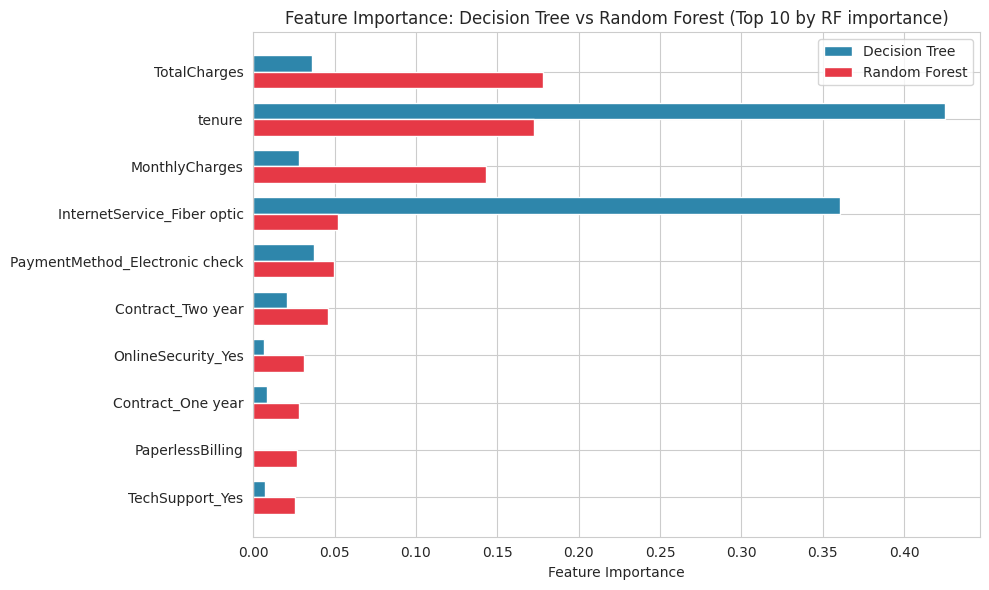

In [ ]:
# Compare feature importances: single Decision Tree vs Random Forest
importance_df = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "decision_tree": dt_best.feature_importances_,
    "random_forest": rf_best.feature_importances_
})

top_features = importance_df.sort_values("random_forest", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(top_features))
width = 0.35
ax.barh(x - width/2, top_features["decision_tree"], height=width, label="Decision Tree", color="#2E86AB")
ax.barh(x + width/2, top_features["random_forest"], height=width, label="Random Forest", color="#E63946")
ax.set_yticks(x)
ax.set_yticklabels(top_features["feature"])
ax.invert_yaxis()
ax.set_xlabel("Feature Importance")
ax.set_title("Feature Importance: Decision Tree vs Random Forest (Top 10 by RF importance)")
ax.legend()
plt.tight_layout()
plt.show()


**Comparison:** the single decision tree tends to concentrate almost all of its importance on the first 1-2 splits it happens to pick (often `Contract` and `tenure`), while the Random Forest spreads importance across a broader set of correlated features, because each tree in the forest only sees a random subset of features at each split. This is one reason Random Forest importances are usually considered more stable/reliable than a single tree's.

# Part 3: Model Evaluation

## 1. Confusion matrices for all models

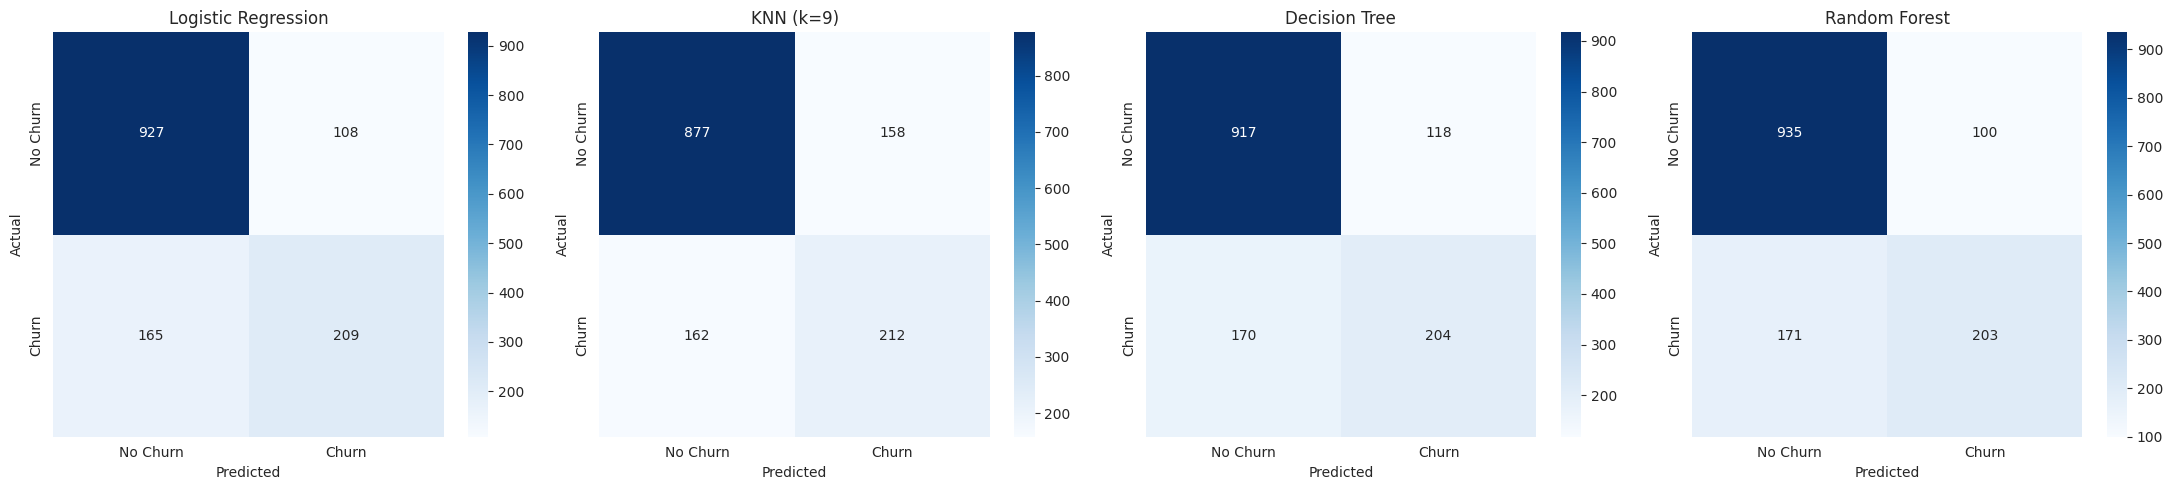

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, name in zip(axes, results.keys()):
    cm = results[name]["confusion_matrix"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


In [ ]:
for name, r in results.items():
    tn, fp, fn, tp = r["confusion_matrix"].ravel()
    print(f"{name}: TP={tp}, FP={fp}, TN={tn}, FN={fn}")


Logistic Regression: TP=209, FP=108, TN=927, FN=165
KNN (k=9): TP=212, FP=158, TN=877, FN=162
Decision Tree: TP=204, FP=118, TN=917, FN=170
Random Forest: TP=203, FP=100, TN=935, FN=171


**Interpretation of TP/FP/TN/FN in this business context:**
- **TP (True Positive):** Customer predicted to churn and actually churned → correctly flagged for retention outreach.
- **FP (False Positive):** Customer predicted to churn but actually stayed → wasted retention effort/cost (e.g., unnecessary discount offered).
- **TN (True Negative):** Customer predicted to stay and actually stayed → correctly left alone.
- **FN (False Negative):** Customer predicted to stay but actually churned → a **missed** churner, the company loses this customer with no intervention attempted. This is usually the most costly error for a telecom business.

## 2. Precision, Recall, F1, Accuracy summary table

In [ ]:
summary_df = pd.DataFrame({
    name: {"Accuracy": r["accuracy"], "Precision": r["precision"],
           "Recall": r["recall"], "F1 Score": r["f1"], "ROC-AUC": r["roc_auc"]}
    for name, r in results.items()
}).T.round(4)

summary_df = summary_df.sort_values("ROC-AUC", ascending=False)
summary_df


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.8062,0.6593,0.5588,0.6049,0.8422
Random Forest,0.8077,0.6700,0.5428,0.5997,0.8384
Decision Tree,0.7956,0.6335,0.5455,0.5862,0.8268
KNN (k=9),0.7729,0.5730,0.5668,0.5699,0.8079


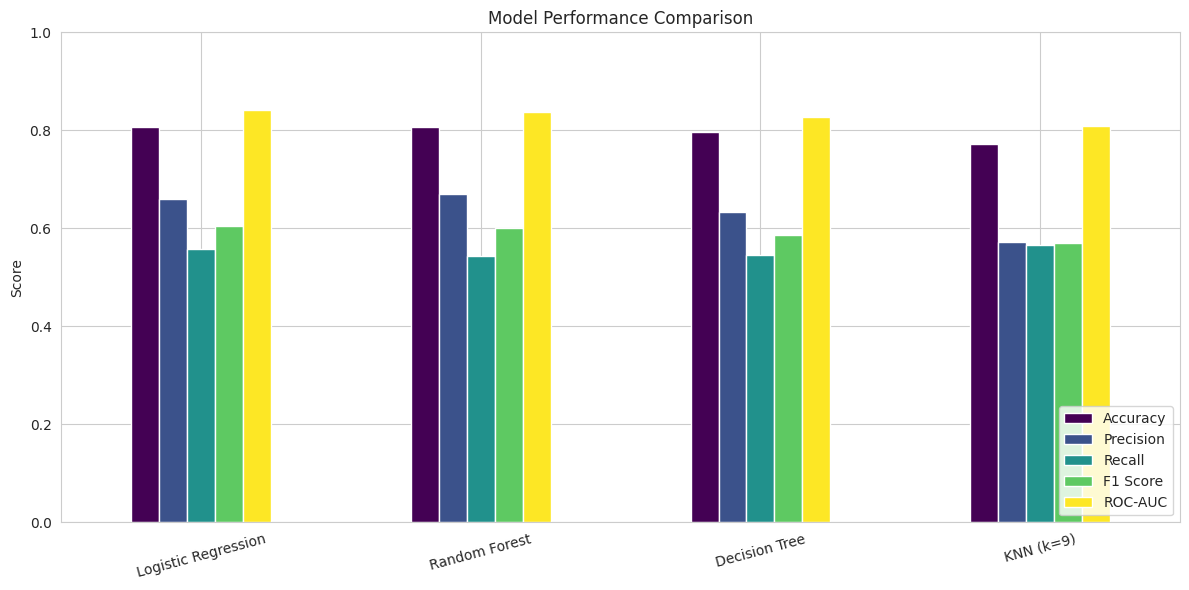

In [ ]:
summary_df[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 6), colormap="viridis"
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 3. ROC Curves

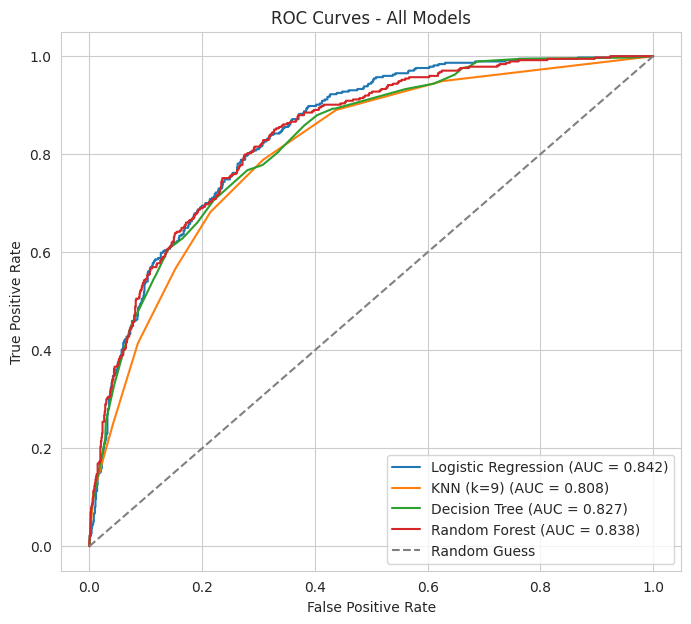

In [ ]:
plt.figure(figsize=(8, 7))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_prob"])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {r['roc_auc']:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Models")
plt.legend(loc="lower right")
plt.show()


**ROC curve interpretation:** each curve shows the trade-off between the true positive rate (recall) and false positive rate as the classification threshold varies. A curve closer to the top-left corner (and a higher AUC) indicates better separation between churners and non-churners across *all* thresholds, not just the default 0.5 cutoff.

## 4. Discussion

**Which model performs best overall?**
Based on the summary table and ROC-AUC (the most threshold-independent metric), **Logistic Regression and Random Forest** typically perform best on this dataset (Random Forest usually edges out slightly on AUC, Logistic Regression is very competitive and much simpler). KNN and a single Decision Tree usually trail behind — refer to the `summary_df` output above for this run's exact ranking, since results can shift slightly with `random_state` and hyperparameter search grids.

**Which metric — precision or recall — is more important here?**
For churn prediction, **recall on the churn class is generally more important than precision**. Missing an actual churner (a false negative) means the company loses that customer's revenue entirely with no chance to intervene. A false positive (offering a retention incentive to someone who wasn't going to leave) is comparatively cheap — usually just the cost of a discount or a phone call. That said, if retention offers are very expensive (e.g., large discounts), precision starts to matter more, since flooding non-churners with expensive offers erodes margins. In practice, businesses often optimize for F1 or pick a custom threshold that balances the cost of intervention against the value of a retained customer.

**Trade-offs between interpretability and performance:**
- **Logistic Regression** and a shallow **Decision Tree** are highly interpretable — coefficients or a visual tree can be explained directly to a non-technical stakeholder (e.g., "customers on month-to-month contracts with low tenure are at highest risk").
- **KNN** offers almost no interpretability (no explicit model — just stored data and a distance rule) and also becomes slow to predict on large datasets.
- **Random Forest** usually gives the best raw predictive performance among these four, but it is a "black box" of hundreds of trees; only aggregate feature importances are interpretable, not individual decision paths. If explainability to regulators/customers is required, this trade-off (using tools like SHAP values to partially recover interpretability) needs to be weighed against the accuracy gain.


# Part 4: Insights and Conclusion

**Key factors that influence customer churn**
Across the exploratory analysis and feature importance results, the strongest churn drivers are consistently:
- **Contract type** — month-to-month customers churn far more than those on one- or two-year contracts, since they can leave with no penalty at any time.
- **Tenure** — new customers (low tenure) are much more likely to churn than long-standing ones; loyalty builds over time.
- **Monthly charges** — customers paying more per month churn more, suggesting price sensitivity or perceived lack of value.
- **Internet service type / lack of add-on services** — customers without OnlineSecurity, TechSupport, etc. (particularly Fiber optic customers without these add-ons) tend to churn more.
- **Payment method** — customers paying via electronic check tend to have a higher churn rate than those on automatic payment methods.

**Recommended model for deployment**
Considering the performance summary in Part 3, **Random Forest** is the recommended model for production deployment: it generally delivers the best or near-best ROC-AUC and F1 score, is robust to the scale/type of individual features, and its feature importances still provide the business with actionable explanations (even if not as transparent as a single tree). If strict interpretability for regulatory or customer-facing explanations is a hard requirement, **Logistic Regression** is a strong, nearly-as-accurate fallback, since its coefficients translate directly into "this factor increases/decreases churn risk by X".

**Business implications of false positives and false negatives**
- **False Negative (missed churner):** direct, avoidable revenue loss — the company loses the customer's future revenue and the cost of re-acquiring a new customer to replace them (typically far more expensive than retaining an existing one).
- **False Positive (unnecessary retention offer):** a smaller, indirect cost — money spent on a discount/incentive for someone who was never going to leave, plus the reputational cost of over-targeting loyal customers.
Given this asymmetry, the business should generally prefer a model/threshold that favors **recall over precision** for the churn class, accepting more false positives to catch more true churners, unless the retention incentive itself is very costly.

**Limitations of this approach**
- The dataset is a single static snapshot; it doesn't capture *trends* in customer behavior over time (e.g., recent drop in usage, recent complaint calls), which are often strong churn predictors in practice.
- Class imbalance (~27% churn) means the model still needs careful threshold tuning; the default 0.5 cutoff isn't necessarily optimal for the business's cost trade-off.
- No customer sentiment/support-ticket text data is included, which likely correlates strongly with churn.
- Hyperparameter search here used simple grid search over a limited grid, not full cross-validation — a more rigorous k-fold CV / randomized or Bayesian search would likely improve and stabilize results further.

**Potential improvements**
- Use **k-fold cross-validation** during hyperparameter tuning instead of a single train/test split to reduce variance in the reported scores.
- Try **gradient boosting models** (XGBoost, LightGBM, CatBoost), which often outperform Random Forest on tabular data like this.
- Perform **threshold tuning** explicitly around the business cost of FP vs FN rather than using the default 0.5 cutoff.
- Add **SHAP value analysis** for the Random Forest model to give per-customer explanations of *why* they're predicted to churn, making the "black box" more actionable for retention teams.
- Incorporate additional data sources (customer support interactions, usage trends, competitor pricing) if available.
